In [27]:
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
student_codes = []
status_records = []
attendance_dict = {}

In [29]:
folder_path = "C:\\Users\\jeeva\\OneDrive\\Desktop\\student_attendance_analysis"
log_file = "student_attendance.log"
with open(os.path.join(folder_path, log_file), "r") as file:
    for line in file:
        words = line.split(" ")
        student_codes.append(words[3])
        status_records.append(words[8].strip())

In [30]:
def calculate_frequency(data_list):
    frequency_dict = {}
    for item in data_list:
        if item not in frequency_dict:
            frequency_dict[item] = 1
        else:
            frequency_dict[item] += 1
    return frequency_dict


In [31]:
attendance_result = calculate_frequency(status_records)
student_result = calculate_frequency(student_codes)

In [32]:
attendance_df = pd.DataFrame(
    list(attendance_result.items()), columns=["Attendance_Status", "Total_Count"])
student_df = pd.DataFrame(
    list(student_result.items()), columns=["Student_Code", "Total_Count"])

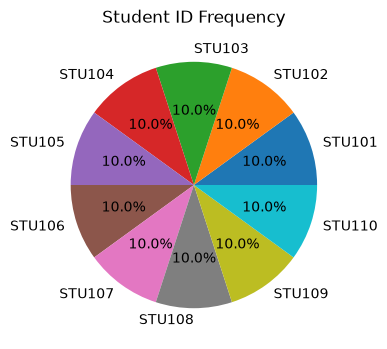

In [33]:
plt.figure(figsize=(10, 4))
plt.pie(
    student_df["Total_Count"],
    labels=student_df["Student_Code"],
    autopct="%1.1f%%")
plt.title("Student ID Frequency")
plt.savefig(os.path.join(folder_path, "studentid pie chart.png"))
plt.show()


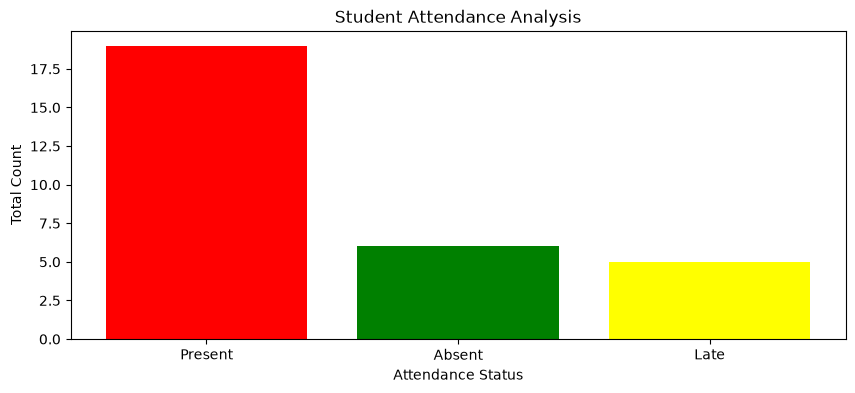

In [34]:
plt.figure(figsize=(10, 4))
colors = ["red", "green", "yellow"]

plt.bar(
    attendance_df["Attendance_Status"],
    attendance_df["Total_Count"],
    color=colors
)
plt.xlabel("Attendance Status")
plt.ylabel("Total Count")
plt.title("Student Attendance Analysis")
plt.savefig(os.path.join(folder_path, "attendance bar chart.png"))
plt.show()

In [35]:
attendance_df.to_csv(os.path.join(folder_path, "student_attendance_frequency.csv"),index=False)
student_df.to_csv(os.path.join(folder_path, "student_id_frequency.csv"),index=False)
